# Car Price Prediction Using Machine Learning

## Oasis Infobyte Data Science Internship — Car Price Prediction

### Project Objective

The objective of this project is to develop machine learning regression models that predict the selling price of a used car based on its characteristics, such as manufacturing year, present price, kilometres driven, fuel type, transmission type, and brand.

### Technologies Used
- Python
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
- Seaborn
- Google Colab

### Models Used
- Linear Regression
- Random Forest Regressor
- Gradient Boosting Regressor

1.Importing Required Libraries

In this step, we import the Python libraries required for data manipulation, visualization, preprocessing, model training, and evaluation.

In [4]:
# Import libraries for data handling
import pandas as pd
import numpy as np

# Import libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import tools for preprocessing and model training
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Import regression models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Import evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.inspection import permutation_importance

# Import Google Colab upload/download tools
from google.colab import files

# Set visualization style
sns.set_theme(style="whitegrid")

# Set a consistent figure size
plt.rcParams["figure.figsize"] = (9, 5)

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Loading the Dataset

We upload the downloaded CarDekho CSV file into Google Colab and load it into a Pandas DataFrame. We then check the dataset dimensions and display the first five records to confirm that the file has loaded correctly.

In [7]:
uploaded = files.upload()

csv_files = [
    filename for filename in uploaded
    if filename.lower().endswith(".csv")
]

if not csv_files:
    raise ValueError(r"C:\Users\yashverdhan\Downloads\car data.csv")

df = pd.read_csv(csv_files[0])

# Standardize column names
df.columns = df.columns.str.strip().str.lower()

print("Dataset loaded successfully!")
print("File:", csv_files[0])
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Saving car data.csv to car data (1).csv
Dataset loaded successfully!
File: car data (1).csv
Dataset shape: (4340, 8)

Column names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


## 3. Initial Data Exploration

Exploratory data analysis helps us understand the structure, data types, and quality of the dataset before training machine-learning models. We examine the column information, missing values, duplicate records, and descriptive statistics to identify possible data-quality issues.

In [8]:
print("Dataset dimensions:", df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)

Dataset dimensions: (4340, 8)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB

Missing values in each column:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Number of duplicate rows:
763

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,4340,1491,Maruti Swift Dzire VDI,69,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,4340.0,NaN,NaN,NaN,2013.090783,4.215344,1992.0,2011.0,2014.0,2016.0,2020.0
selling_price,4340.0,NaN,NaN,NaN,504127.311751,578548.736139,20000.0,208749.75,350000.0,600000.0,8900000.0
km_driven,4340.0,NaN,NaN,NaN,66215.777419,46644.102194,1.0,35000.0,60000.0,90000.0,806599.0
fuel,4340,5,Diesel,2153,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_type,4340,3,Individual,3244,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,4340,2,Manual,3892,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,4340,5,First Owner,2832,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Data Cleaning and Feature Engineering

Data cleaning improves the quality of the dataset before model training. We remove duplicate records, handle missing values, validate numerical values, and create additional features.

The `car_age` feature represents the approximate age of a car, while `brand` extracts the first word from the car name. The selling price is our target variable, so it will not be used as an input feature.

In [9]:
# Required columns in our dataset
required_columns = [
    "name", "year", "selling_price", "km_driven",
    "fuel", "seller_type", "transmission", "owner"
]

missing_columns = set(required_columns) - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Keep only the required columns
df = df[required_columns].copy()

# Convert numeric columns safely
for col in ["year", "selling_price", "km_driven"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with missing required values
df = df.dropna(subset=required_columns)

# Remove duplicate records
df = df.drop_duplicates().copy()

# Remove invalid numerical values
df = df[
    (df["selling_price"] > 0) &
    (df["km_driven"] >= 0) &
    (df["year"] >= 1980) &
    (df["year"] <= 2026)
].copy()

# Clean text columns
text_columns = [
    "name", "fuel", "seller_type",
    "transmission", "owner"
]

for col in text_columns:
    df[col] = df[col].astype(str).str.strip()

# Remove empty text values
df = df[
    ~df[text_columns].isin(["", "nan", "None"]).any(axis=1)
].copy()

# Feature engineering
df["car_age"] = 2026 - df["year"]
df["brand"] = df["name"].str.split().str[0]

df = df.reset_index(drop=True)

print("Data cleaning completed!")
print("Cleaned dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

display(df.head())

Data cleaning completed!
Cleaned dataset shape: (3577, 10)

Missing values:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
car_age          0
brand            0
dtype: int64


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,car_age,brand
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner,19,Maruti
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner,19,Maruti
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner,14,Hyundai
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner,9,Datsun
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner,12,Honda


## 5. Selling Price Distribution

We visualize the distribution of selling prices to understand the price ranges in the dataset. This helps identify whether most cars fall within lower price ranges and whether a small number of expensive cars create a skewed distribution.

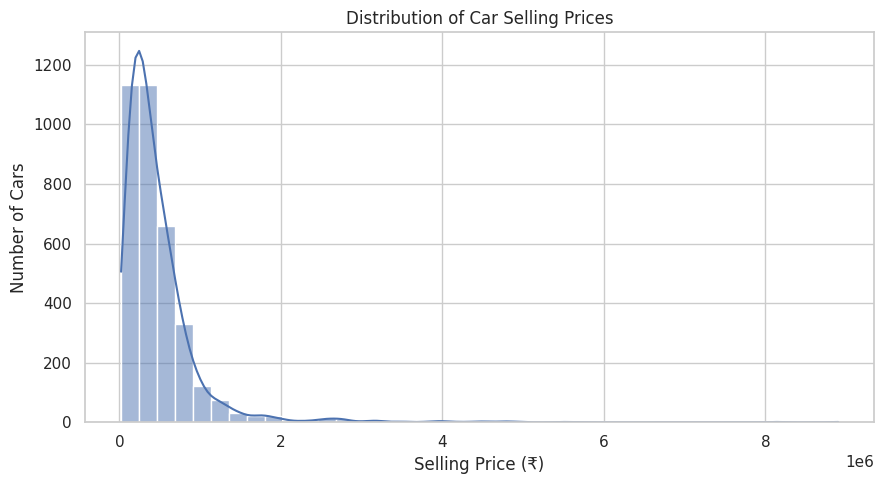

In [10]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="selling_price",
    bins=40,
    kde=True
)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price (₹)")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()

## 6. Relationship Between Car Age and Selling Price

A car's age can influence its resale value. We use a scatter plot to examine the relationship between car age and selling price and identify general pricing patterns.

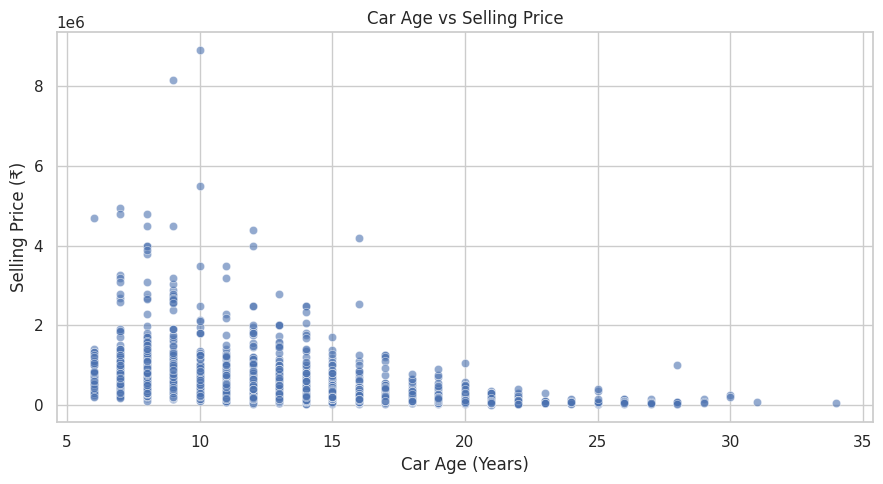

In [11]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="car_age",
    y="selling_price",
    alpha=0.6
)

plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price (₹)")
plt.tight_layout()
plt.show()

## 7. Relationship Between Kilometres Driven and Selling Price

The distance travelled by a car may influence its resale value. This visualization helps us examine how selling prices vary with the number of kilometres driven.

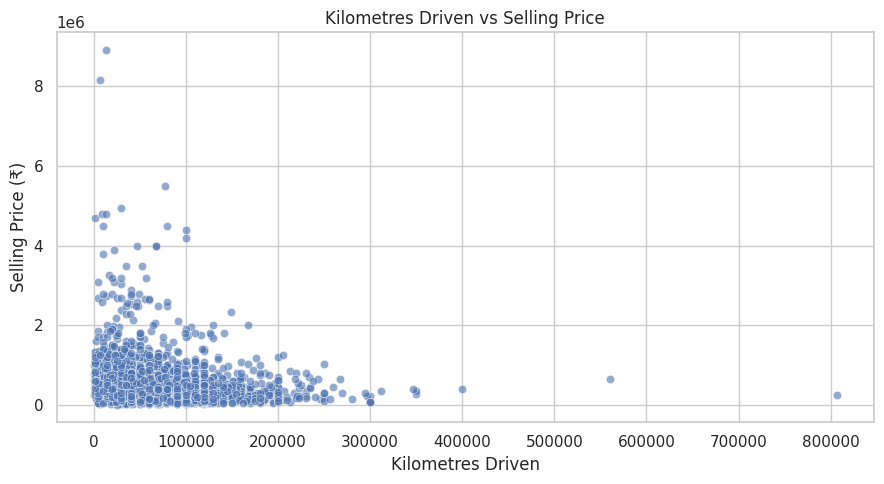

In [12]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="km_driven",
    y="selling_price",
    alpha=0.6
)

plt.title("Kilometres Driven vs Selling Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price (₹)")
plt.tight_layout()
plt.show()

## 8. Selling Price by Fuel Type and Transmission

Categorical features such as fuel type and transmission may help explain differences in used-car prices. We compare their selling-price distributions using box plots.

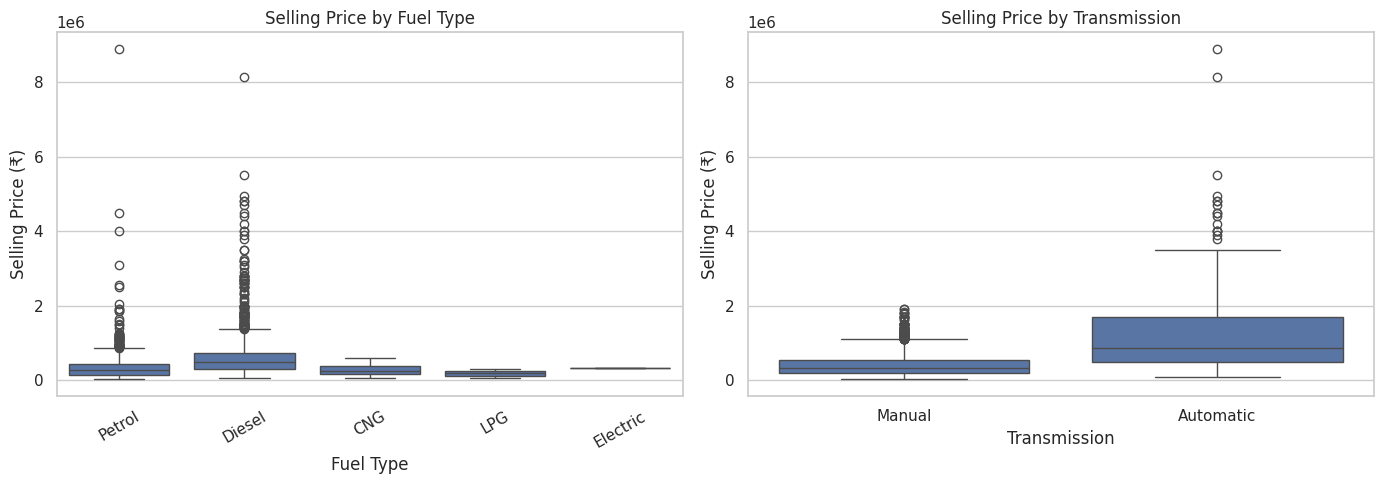

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df,
    x="fuel",
    y="selling_price",
    ax=axes[0]
)
axes[0].set_title("Selling Price by Fuel Type")
axes[0].set_xlabel("Fuel Type")
axes[0].set_ylabel("Selling Price (₹)")
axes[0].tick_params(axis="x", rotation=30)

sns.boxplot(
    data=df,
    x="transmission",
    y="selling_price",
    ax=axes[1]
)
axes[1].set_title("Selling Price by Transmission")
axes[1].set_xlabel("Transmission")
axes[1].set_ylabel("Selling Price (₹)")

plt.tight_layout()
plt.show()

## 9. Feature Selection

We separate the dataset into input features and the target variable. The target is `selling_price`, which the model must predict. The input features include the car's age, kilometres driven, fuel type, seller type, transmission, owner history, and brand.

We exclude the original year and full car name because car age is derived from year, and brand is extracted from the full name.

In [14]:
feature_columns = [
    "car_age",
    "km_driven",
    "fuel",
    "seller_type",
    "transmission",
    "owner",
    "brand"
]

X = df[feature_columns].copy()
y = df["selling_price"].copy()

numeric_features = ["car_age", "km_driven"]

categorical_features = [
    "fuel",
    "seller_type",
    "transmission",
    "owner",
    "brand"
]

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget variable: selling_price")

Input feature shape: (3577, 7)
Target shape: (3577,)

Input features:
['car_age', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'brand']

Target variable: selling_price


## 10. Training and Testing Data Split

We divide the dataset into training and testing sets. The training set is used to learn patterns, while the testing set evaluates how well the trained model predicts prices for unseen records. We use an 80:20 split and a fixed random state for reproducibility.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 2861
Testing records: 716


## 11. Data Preprocessing

Machine-learning models require categorical data to be converted into numerical representations. We use one-hot encoding for categorical features and standard scaling for numerical features.

A preprocessing pipeline ensures the same transformations are applied consistently during training and prediction.

In [16]:
numeric_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## 12. Model Training

We train and compare three regression algorithms:

1. **Linear Regression:** Establishes a simple baseline model.
2. **Random Forest Regressor:** Combines multiple decision trees to learn complex patterns.
3. **Gradient Boosting Regressor:** Builds trees sequentially to improve prediction performance.

Each model uses the same preprocessing pipeline and training data for a fair comparison.

In [17]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

trained_models = {}

for model_name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[model_name] = pipeline

    print(f"{model_name} trained successfully!")

Linear Regression trained successfully!
Random Forest trained successfully!
Gradient Boosting trained successfully!


## 13. Model Evaluation

We evaluate each model using three regression metrics:

- **MAE (Mean Absolute Error):** The average absolute difference between actual and predicted prices.
- **RMSE (Root Mean Squared Error):** Gives greater weight to larger prediction errors.
- **R² Score:** Measures how much variation in the target is explained by the model. A higher score generally indicates better performance on the test set.

MAE and RMSE are expressed in the dataset's selling-price units, which are rupees.

In [18]:
results = []
predictions = {}

for model_name, pipeline in trained_models.items():
    y_pred = pipeline.predict(X_test)
    predictions[model_name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": model_name,
        "MAE (₹)": mae,
        "RMSE (₹)": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="MAE (₹)",
    ascending=True
).reset_index(drop=True)

display(results_df.round(2))

,Model,MAE (₹),RMSE (₹),R2 Score
0,Random Forest,157686.48,363871.46,0.59
1,Gradient Boosting,159547.62,370976.18,0.57
2,Linear Regression,179642.88,384722.72,0.54


## 14. Model Performance Comparison

We compare the models using their Mean Absolute Error (MAE). A lower MAE indicates that predictions are closer to actual selling prices on average. We also retain RMSE and R² scores to evaluate different aspects of model performance.

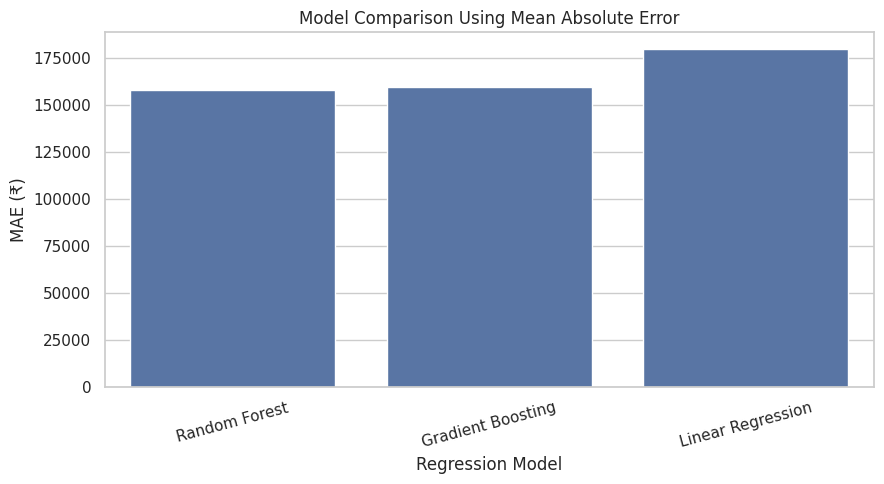

Best model by test MAE: Random Forest


In [19]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE (₹)"
)

plt.title("Model Comparison Using Mean Absolute Error")
plt.xlabel("Regression Model")
plt.ylabel("MAE (₹)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model by test MAE:", best_model_name)

## 15. Actual vs Predicted Prices

We compare actual selling prices with the prices predicted by the best model. Points closer to the diagonal reference line indicate more accurate predictions.

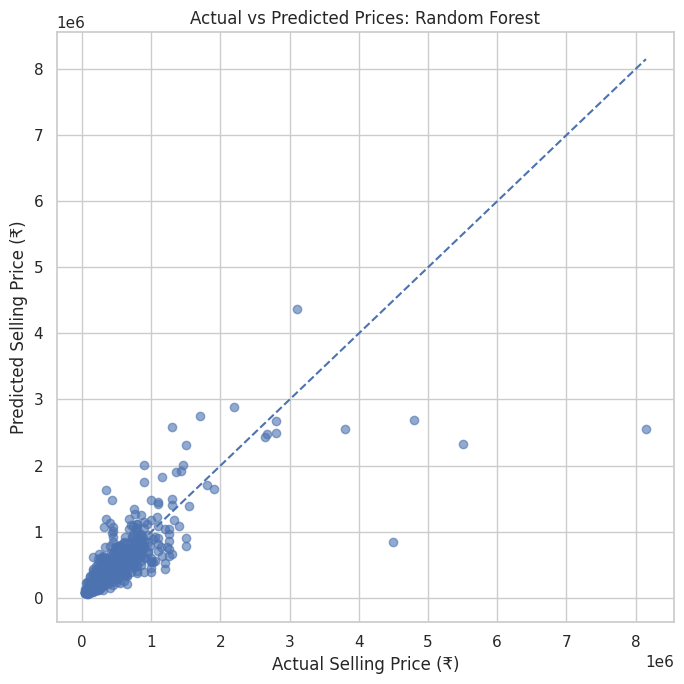

In [20]:
best_predictions = predictions[best_model_name]

plt.figure(figsize=(7, 7))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.6
)

min_value = min(y_test.min(), best_predictions.min())
max_value = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title(f"Actual vs Predicted Prices: {best_model_name}")
plt.xlabel("Actual Selling Price (₹)")
plt.ylabel("Predicted Selling Price (₹)")
plt.tight_layout()
plt.show()

## 16. Residual Analysis

A residual is the difference between an actual price and a predicted price. We examine residuals to understand prediction errors and identify patterns that may indicate the model does not fit some records well.

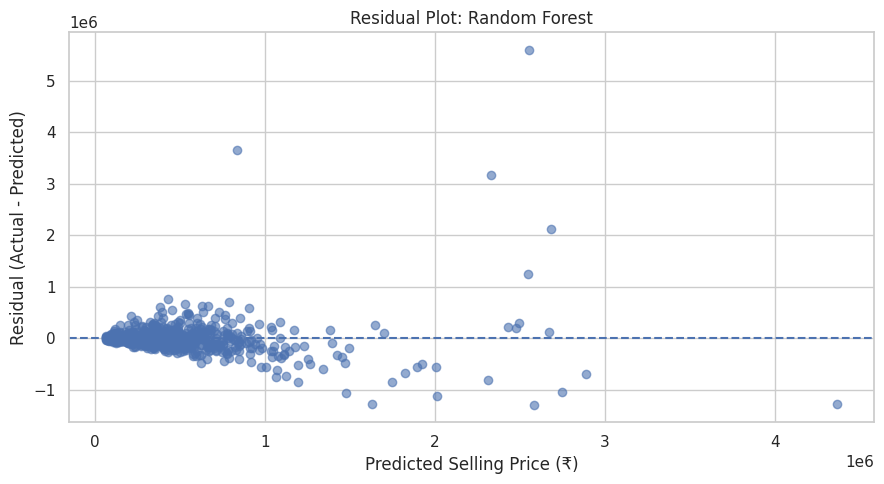

In [21]:
residuals = y_test - best_predictions

plt.figure(figsize=(9, 5))

plt.scatter(
    best_predictions,
    residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title(f"Residual Plot: {best_model_name}")
plt.xlabel("Predicted Selling Price (₹)")
plt.ylabel("Residual (Actual - Predicted)")
plt.tight_layout()
plt.show()

## 17. Feature Importance Analysis

We use permutation importance to estimate how much the model's performance changes when one input feature is shuffled. A larger importance value indicates that the feature is more useful to the trained model's predictions. This helps us interpret which characteristics contribute most to price prediction.

,Feature,Importance
0,car_age,108158.1747
2,fuel,54505.7955
4,transmission,46116.5043
6,brand,39541.5836
1,km_driven,12698.6861
3,seller_type,2338.9180
5,owner,-28.0141


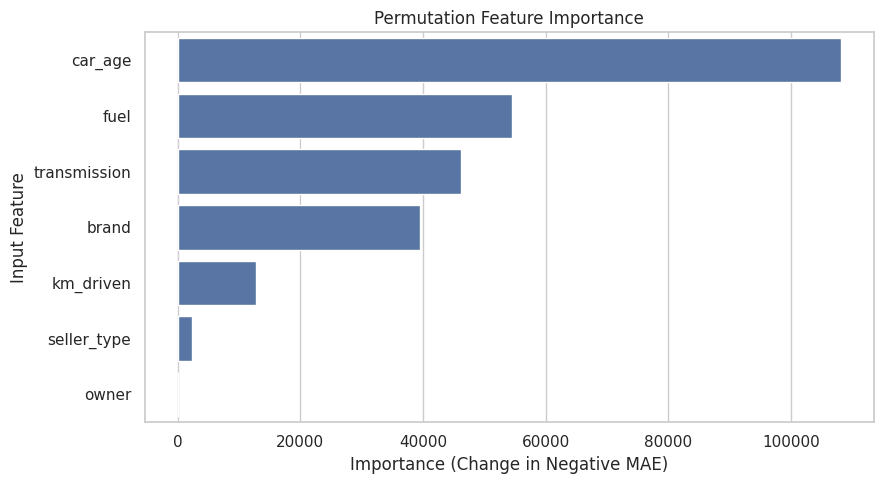

In [22]:
importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean
}).sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.round(4))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Permutation Feature Importance")
plt.xlabel("Importance (Change in Negative MAE)")
plt.ylabel("Input Feature")
plt.tight_layout()
plt.show()

## 18. Sample Car Price Prediction

We test the trained model on one record from the test set. This demonstrates how the model uses the car's characteristics to estimate its selling price. The prediction is an estimate, not a guaranteed market price.

In [23]:
sample_car = X_test.iloc[[0]]
actual_price = y_test.iloc[0]

predicted_price = best_model.predict(sample_car)[0]

print("Sample car details:")
display(sample_car)

print(f"Actual selling price: ₹{actual_price:,.2f}")
print(f"Predicted selling price: ₹{predicted_price:,.2f}")
print(
    f"Absolute prediction error: "
    f"₹{abs(actual_price - predicted_price):,.2f}"
)

Sample car details:


,car_age,km_driven,fuel,seller_type,transmission,owner,brand
907,8,20000,Petrol,Individual,Manual,First Owner,Maruti


Actual selling price: ₹270,000.00
Predicted selling price: ₹578,831.65
Absolute prediction error: ₹308,831.65


## 19. Exporting Model Results

We save the model-comparison table and the cleaned dataset as CSV files. These outputs can be included in the project repository alongside the notebook and README documentation.

In [24]:
results_df.to_csv(
    "car_price_model_comparison.csv",
    index=False
)

df.to_csv(
    "cleaned_car_dataset.csv",
    index=False
)

print("Exported files successfully:")
print("- car_price_model_comparison.csv")
print("- cleaned_car_dataset.csv")

Exported files successfully:
- car_price_model_comparison.csv
- cleaned_car_dataset.csv


## 20. Conclusion

In this project, we developed a machine-learning workflow to predict used-car selling prices using the CarDekho dataset. We performed data cleaning, feature engineering, exploratory data analysis, preprocessing, and regression-model training.

We evaluated Linear Regression, Random Forest, and Gradient Boosting using MAE, RMSE, and R². We then compared their test performance, examined prediction errors, and analyzed feature importance.

The project demonstrates how historical vehicle information can support used-car price estimation. The model's performance depends on the quality and coverage of the dataset, and its predictions should be treated as estimates rather than exact market prices.